    Single allele groupped structue models.

In [1]:
import pomegranate.io
from pomegranate import *

In [2]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


In [3]:
import training_parameters
from peptides_utils import defineClass, defineOrganism, make_logo_for_data
from data_reading_methods import remove_unused_lengths, transform_data_to_properties_and_join_alleles, calculate_weights_based_on_length_counts

# 1. Read data

In [4]:
hmm_params = training_parameters.ExperimentParams(experiment_name="multiple_single_allele_models")
hmm_params.data_scenario_params = training_parameters.SimulatedDataParams()

In [5]:
model_training_params = hmm_params.model_training_params

In [6]:
hmm_params.data_scenario_params.simulated_exact_file_name

'sim_data_motifs_5_ratio_(0.05, 0.05, 0.15, 0.35, 0.4)_lengths_(8,)_noize_0.45.csv'

In [7]:
from data_reading_methods import get_available_alleles, get_train_test_data, join_dicts

per_allele_per_kfold_per_length_binders_train, \
per_allele_per_kfold_per_length_binders_test, additional_data = get_train_test_data(hmm_params)

PARSED_ALLELES = list(per_allele_per_kfold_per_length_binders_train.keys())

print(sorted(PARSED_ALLELES))

Will read files from the folder G:\My Drive\Work\ITMO\data\multiple_single_allele_models\simulated_data
['dummy_allele']


In [8]:
import pandas as pd
data_params = hmm_params.data_scenario_params
DATA_PATH = data_params.input_data_path
simulated_exact_file = data_params.simulated_exact_file_name
dummy_allele_name = data_params.dummy_allele_name
simulated_scenario = data_params.simulated_scenario
SIMULATED_DATA_PATH = f"{DATA_PATH}/{simulated_scenario}/{simulated_exact_file}"
ALLELES = [dummy_allele_name]

allele_df = pd.read_csv(SIMULATED_DATA_PATH, sep=";")

In [9]:
simulated_exact_file

'sim_data_motifs_5_ratio_(0.05, 0.05, 0.15, 0.35, 0.4)_lengths_(8,)_noize_0.45.csv'

In [10]:
allele_df

,peptide,core,core_start,length,allele,noize,binder
0,CGRMMEFIQYLGKKP,EFIQYLGKK,5,15,Dummy_allele_4,0,1
1,PIHDEQQCVLHKCGK,DEQQCVLHK,3,15,Dummy_allele_4,0,1
2,PSPEWHKGYHVAH,PSPEWHKGY,0,13,Dummy_allele_3,1,1
3,NQRPMFCRQVNAVMP,RPMFCRQVN,2,15,Dummy_allele_4,1,1
4,ENEITLEHKGHYYH,ENEITLEHK,0,14,Dummy_allele_4,0,1
...,...,...,...,...,...,...,...
11995,FRPNDIEQTLTTKYYSRW,DIEQTLTTK,4,18,Dummy_allele_4,0,1
11996,GHKSMLEFVDSKKRA,KSMLEFVDS,2,15,Dummy_allele_3,0,1
11997,RWWFKKYGFSQYKTVIY,WFKKYGFSQ,2,17,Dummy_allele_2,0,1
11998,FRAHKKLKQLHTHWP,HKKLKQLHT,3,15,Dummy_allele_3,0,1


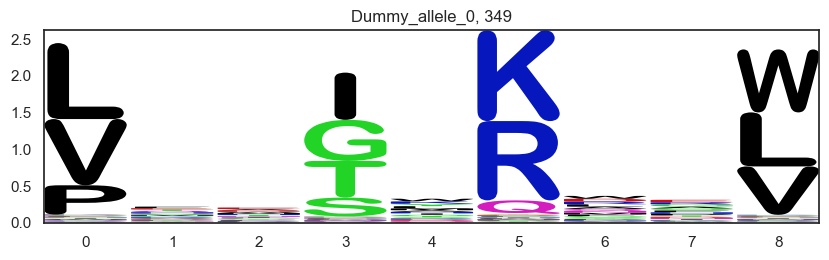

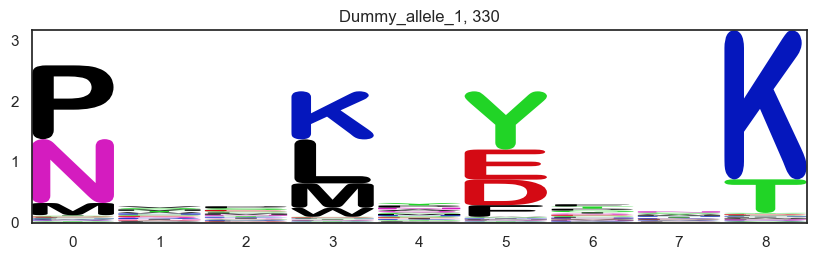

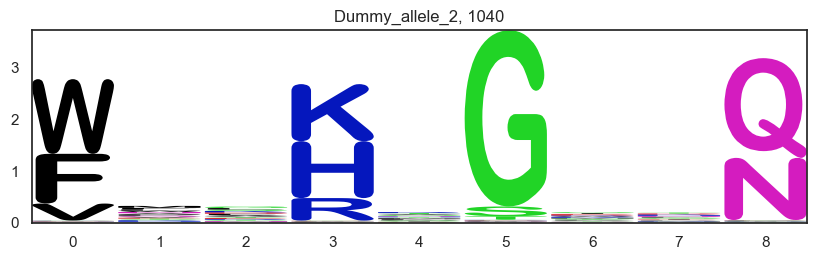

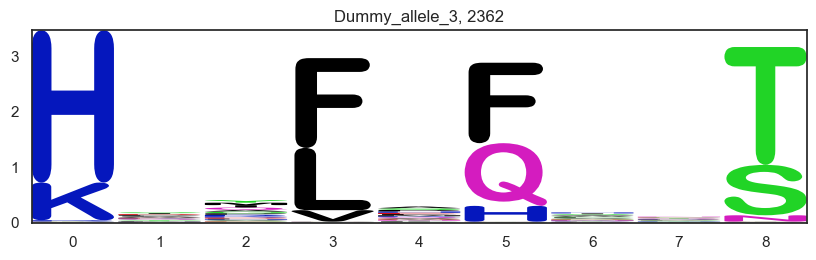

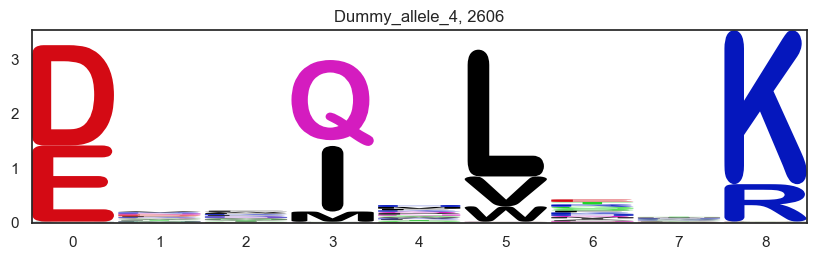

In [11]:
for i in range(len(allele_df.allele.unique())):
    name = f"Dummy_allele_{i}"
    make_logo_for_data(allele_df[(allele_df.allele == name) & (allele_df.noize == 0)].core.values, name=name)

# 2. Prepare data and weithgs for training

In [12]:
model_training_params: training_parameters.ModelTrainingParams = hmm_params.model_training_params
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['HLA-DRB1*04:01']]
model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['dummy_allele']]
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['decoy-allele-78']]
# remove unused lengths (used are specified in ModelTrainingParams.model_training_params
per_allele_per_kfold_per_length_binders_train = remove_unused_lengths(per_allele_per_kfold_per_length_binders_train, experiment_params=hmm_params)
per_allele_per_kfold_per_length_binders_test = remove_unused_lengths(per_allele_per_kfold_per_length_binders_test,experiment_params=hmm_params)

# transform to properties if needed and join multiple alleles
train_data, test_data, NEW_ALLELES, \
old_train_data, old_test_data, OLD_ALLELES = transform_data_to_properties_and_join_alleles(
    per_allele_per_kfold_per_length_binders_train,
    per_allele_per_kfold_per_length_binders_test,
    hmm_params.model_training_params
)
# Calculate weights for the training data based on peptide couns/lengths for unmerged data
train_data_weigths = calculate_weights_based_on_length_counts(old_train_data, experiment_params=hmm_params)

dummy_allele
Length 16: dummy_allele - 1671 
Length 17: dummy_allele - 1110 
Length 18: dummy_allele - 741 
Length 12: dummy_allele - 311 
Length 13: dummy_allele - 917 
Length 14: dummy_allele - 1309 
Length 15: dummy_allele - 5941 


## Check: Motif for train data

In [13]:
train_data.keys()

dict_keys(['dummy_allele'])

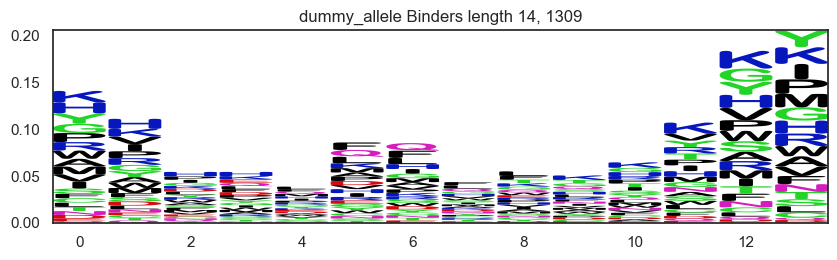

In [14]:
target_allele = hmm_params.model_training_params.alleles_to_use[0]
target_length = hmm_params.model_training_params.lengths_to_use[2]
peptides = train_data[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# 3. Models

In [15]:
from hmm_logic_methods import train_model_prepared,  \
    train_model_batched, save_model, \
    add_more_states_and_reset_transitions, \
    build_model_based_on_params, \
    prepare_multiple_models, train_multiple_models, \
reorder_models_by_score_and_flatten_to_by_name_list, hierarchically_train_splited_models
from hmm_visualization_methods import *

C:\Users\denkl\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Check generate sample model to ensure that it is looking like we want

In [16]:
prepared_model = build_model_based_on_params(hmm_params.model_training_params, verbose=True)

with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

plot_distributions_for_states(prepared_model,"test", horizontal=False,
                              discrete = hmm_params.model_training_params.aa_labels_training,
                              initial_params = hmm_params.model_training_params.initial_params)
make_pyviz_graph(prepared_model, "test", precision=3)

start cycles added 1
end cycles added 1
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]


<class 'pyvis.network.Network'> |N|=13 |E|=16

In [17]:
hmm_params.model_training_params.decrease_anchor_aas_steps

1

## Prepare and train models

In [18]:
#prepare models
per_allele_per_run_per_split_prepared_models = prepare_multiple_models(hmm_params)
#do training
result_models, \
result_histories =  train_multiple_models(
    prepared_models=per_allele_per_run_per_split_prepared_models,
    train_data=train_data,
    test_data=test_data,
    train_data_weigths=train_data_weigths,
    experiment_params=hmm_params,
    subfolder_to_safe_result="root")


Allele dummy_allele: root[0000] root[0001] root[0002] root[0003] root[0004] root[0005] root[0006] root[0007] root[0008] root[0009] root[0010] root[0011] root[0012] root[0013] root[0014] root[0015] root[0016] root[0017] root[0018] root[0019] root[0020] root[0021] root[0022] root[0023] root[0024] root[0025] root[0026] root[0027] root[0028] root[0029]  


In [19]:
per_name_models, per_name_histories, original_alelle_sortings = reorder_models_by_score_and_flatten_to_by_name_list(histories=result_histories,
                                                                models=result_models, experiment_params=hmm_params,subfolder_to_safe_result="root" )
save_all_visualization_results(per_name_models, per_name_histories, experiment_params=hmm_params, subfolder_to_safe_result="root")


ModelGraph
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 
Distributions
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 
PyViz


# Splitting

iteration br1
Starting split br1
Number of models used for this split is 12
split is 5409/6591
Allele dummy_allele: br11[0000] br11[0001] br11[0002] br11[0003] br11[0004] br11[0005] br11[0006] br11[0007] br11[0008] br11[0009] br11[0010] br11[0011] br11[0012] br11[0013] br11[0014] br11[0015] br11[0016] br11[0017] br11[0018] br11[0019] br11[0020] br11[0021] br11[0022] br11[0023] br11[0024] br11[0025] br11[0026] br11[0027] br11[0028] br11[0029]  
Allele dummy_allele: br12[0000] br12[0001] br12[0002] br12[0003] br12[0004] br12[0005] br12[0006] br12[0007] br12[0008] br12[0009] br12[0010] br12[0011] br12[0012] br12[0013] br12[0014] br12[0015] br12[0016] br12[0017] br12[0018] br12[0019] br12[0020] br12[0021] br12[0022] br12[0023] br12[0024] br12[0025] br12[0026] br12[0027] br12[0028] br12[0029]  
Enrichment
enrichment iteration 0
Number of models used for this split is 9
Number of models used for this split is 9
split is 5823/6177
Allele dummy_allele: br11[0000] br11[0001] br11[0002] br11[000

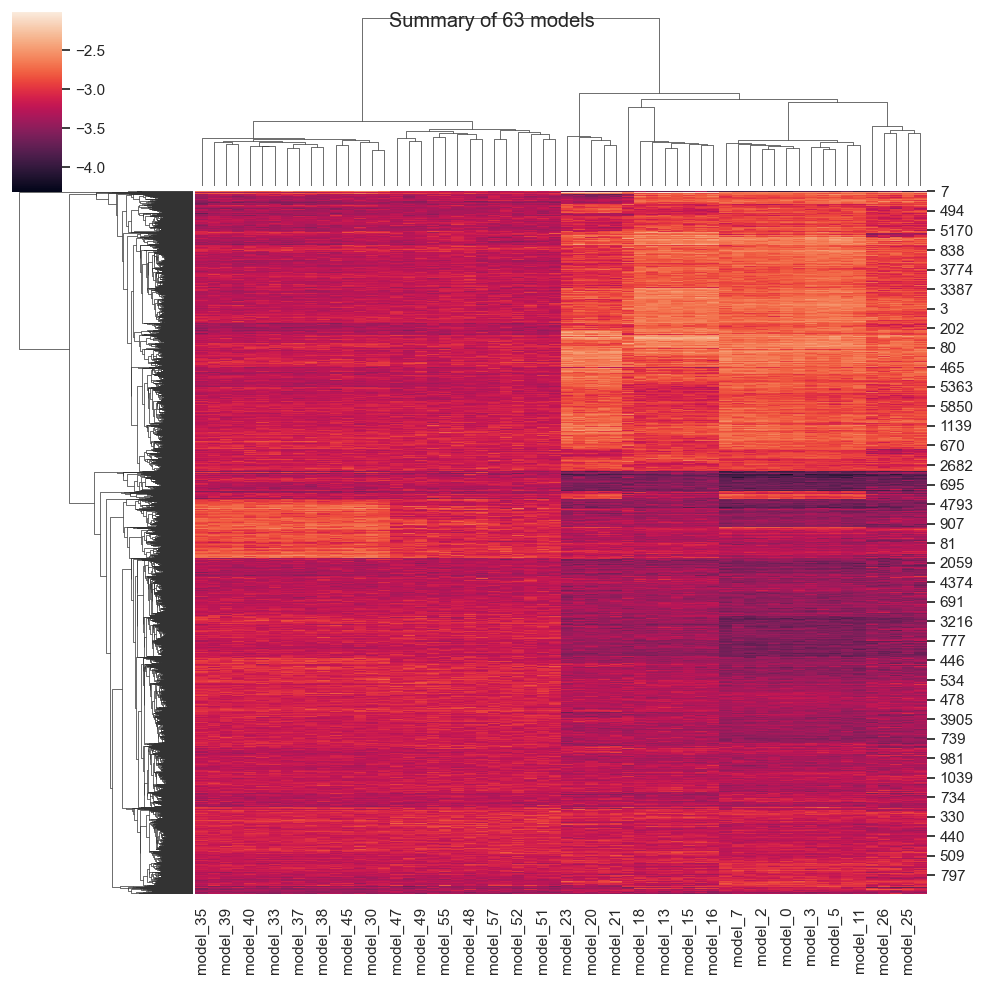

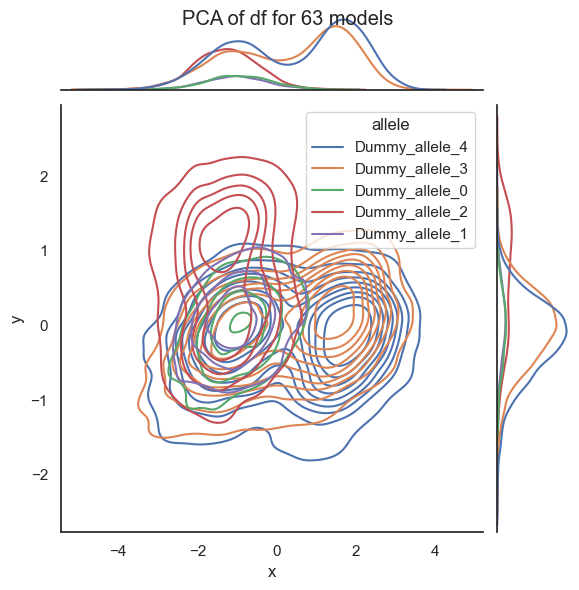

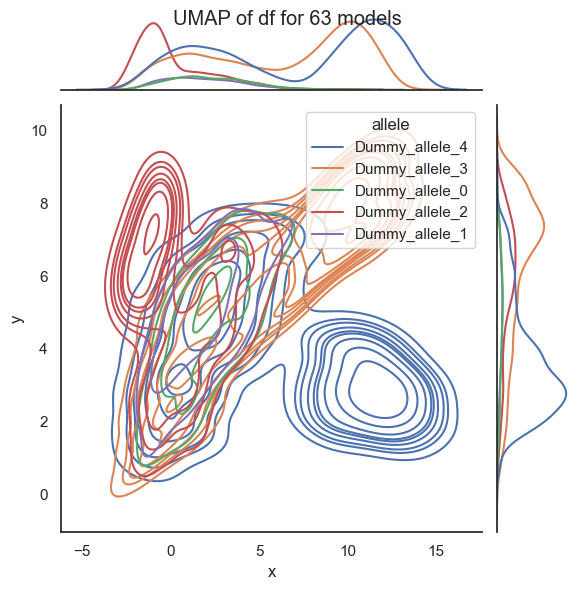

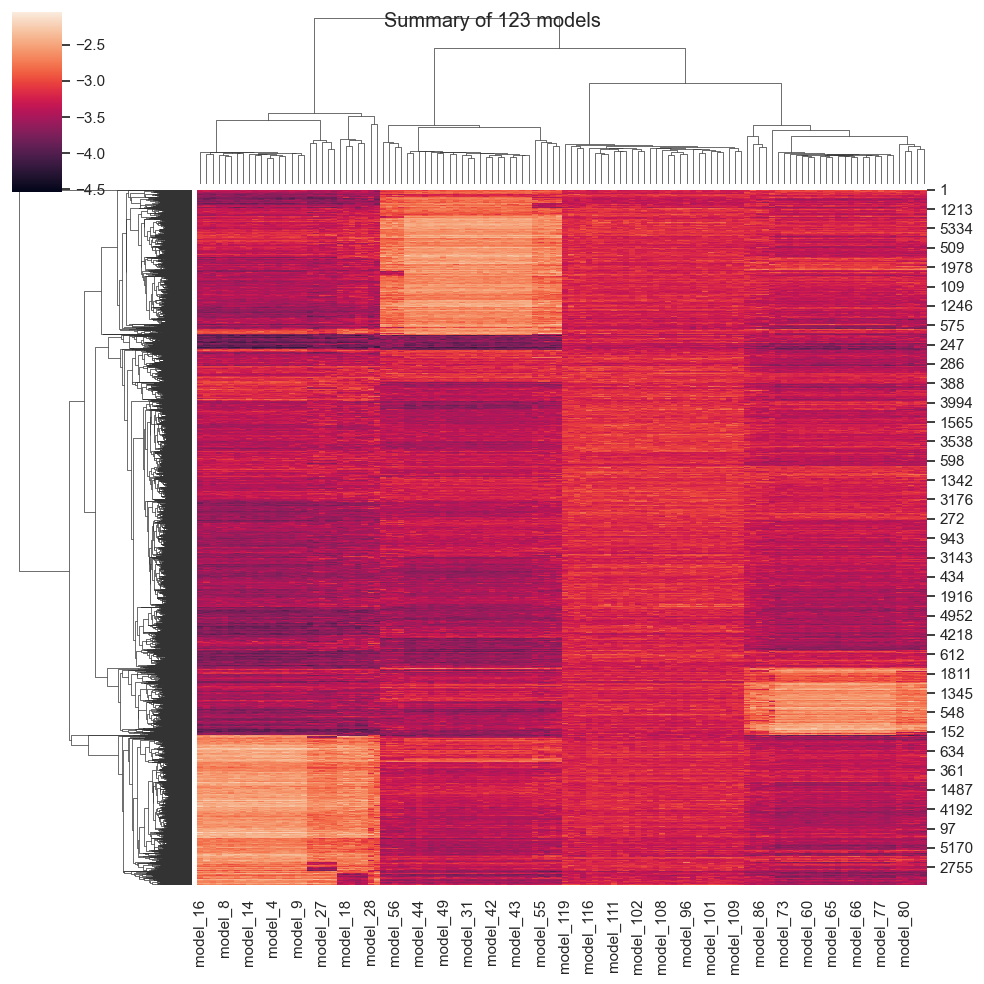

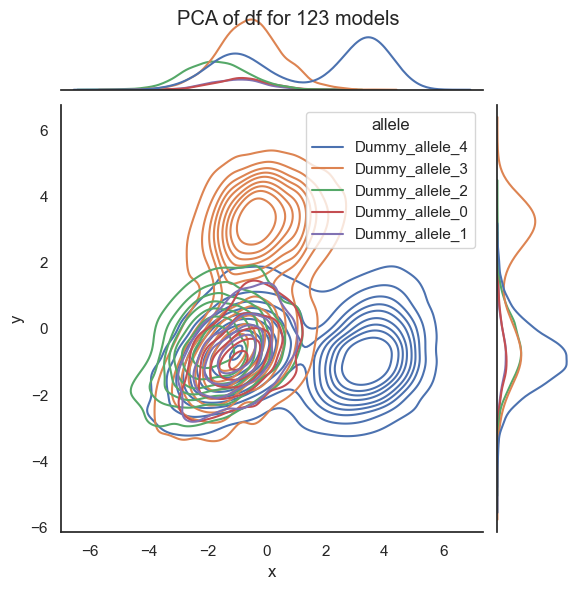

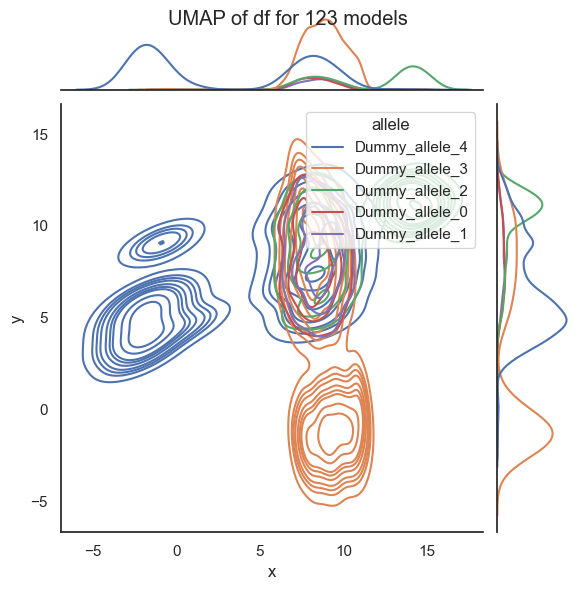

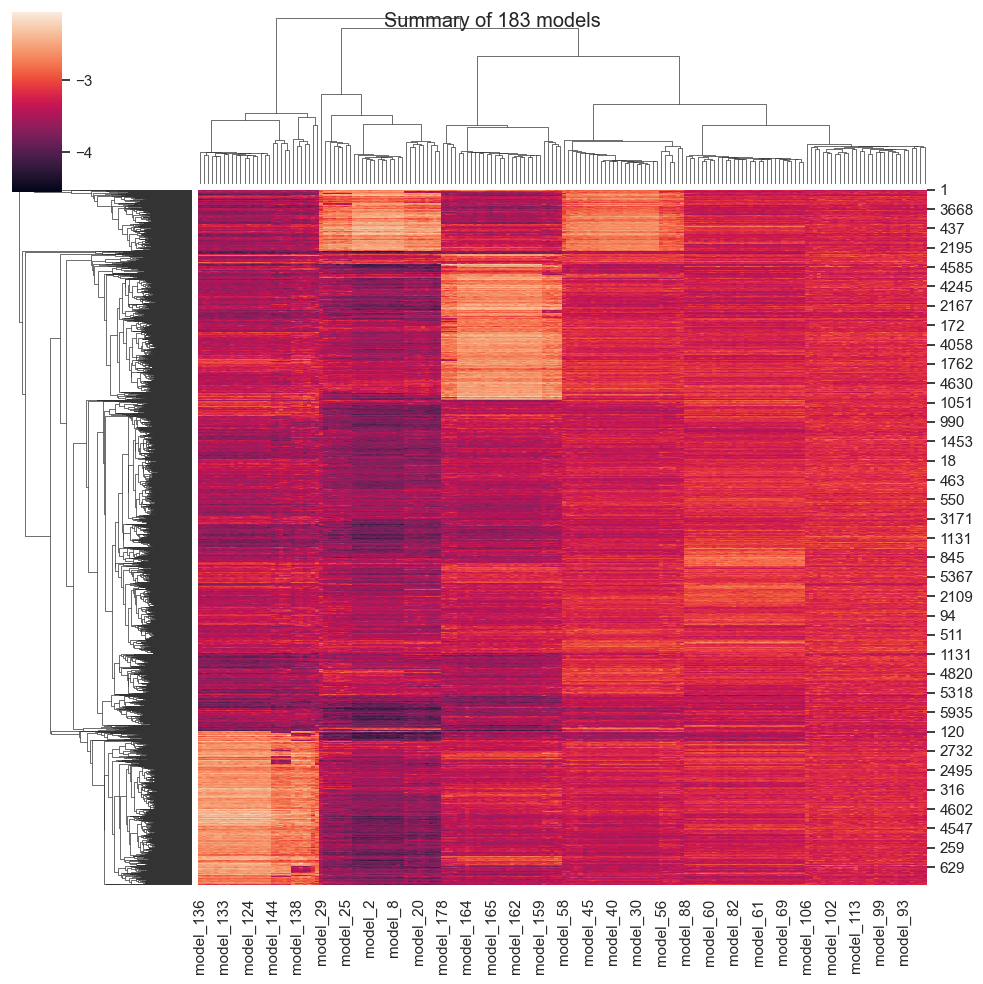

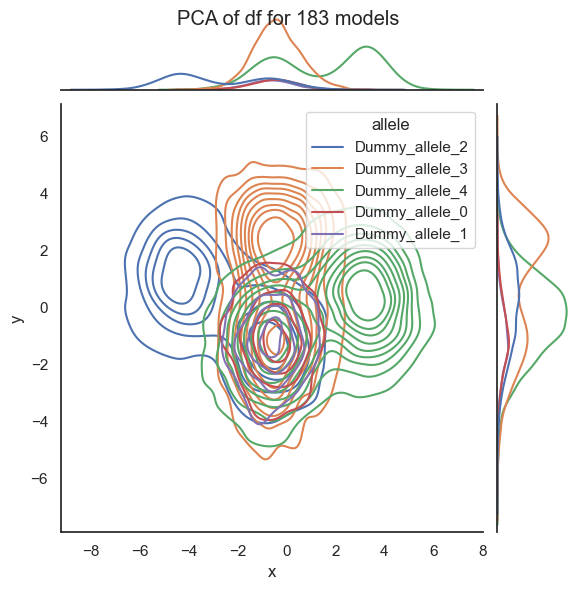

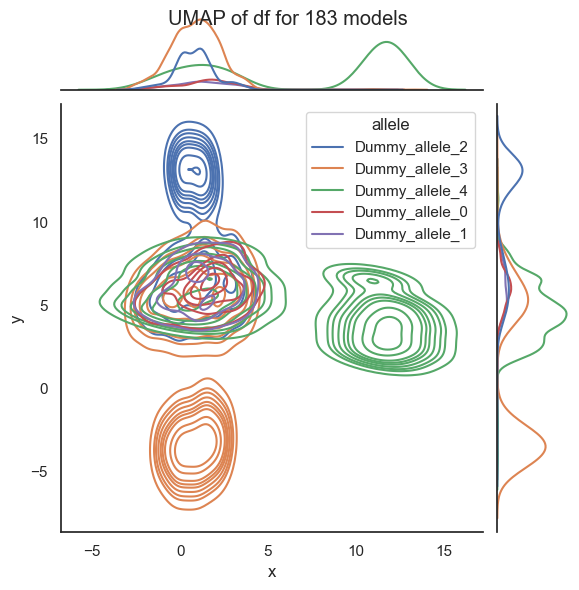

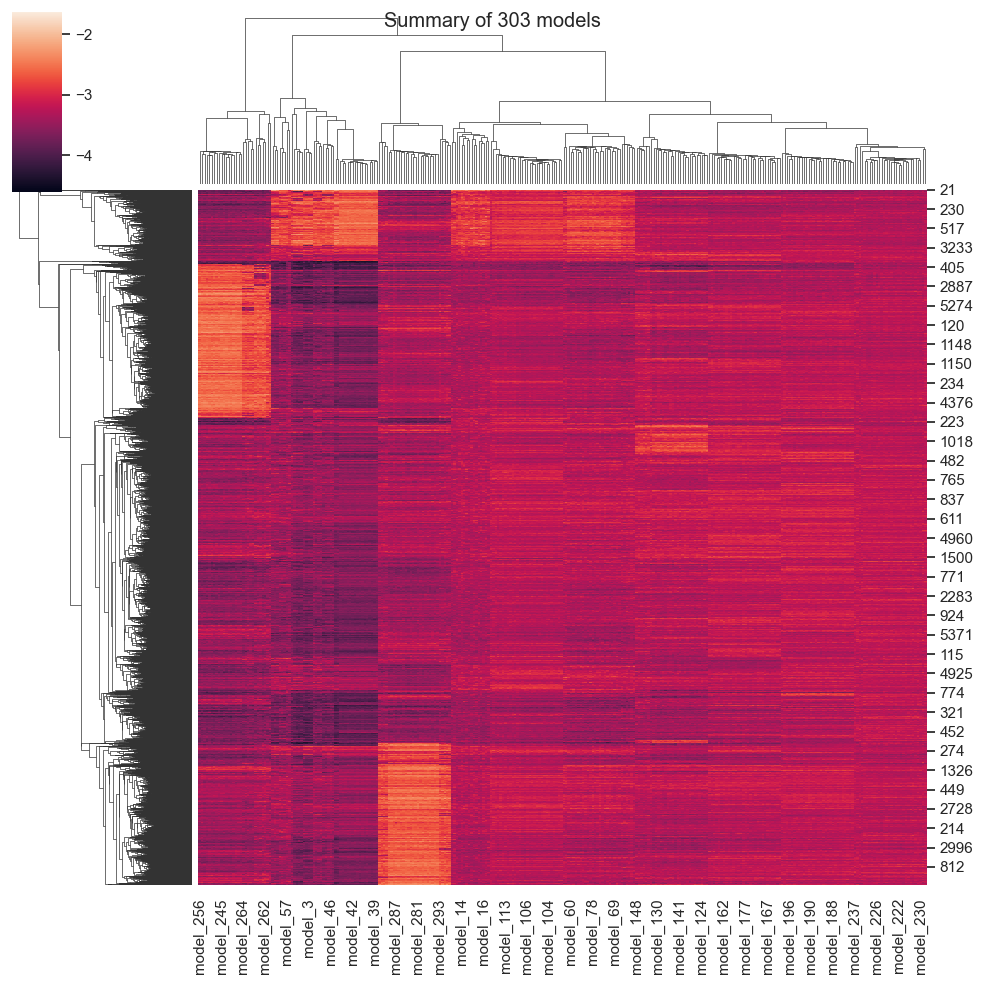

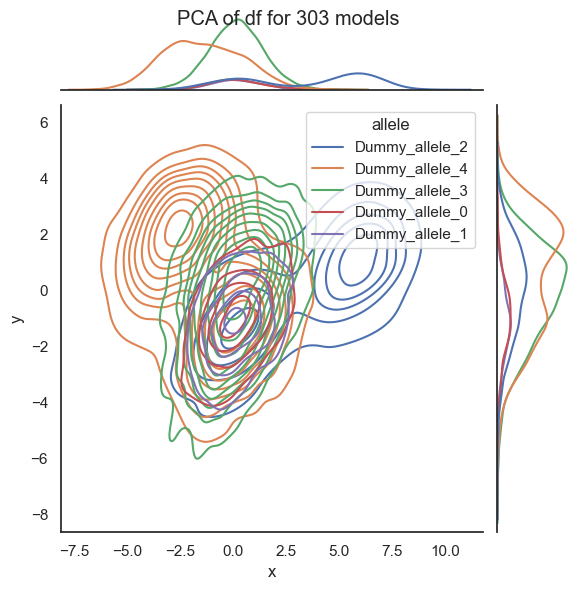

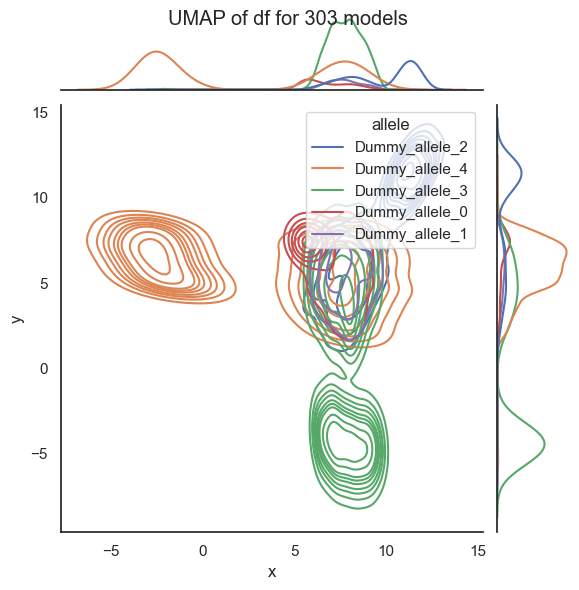

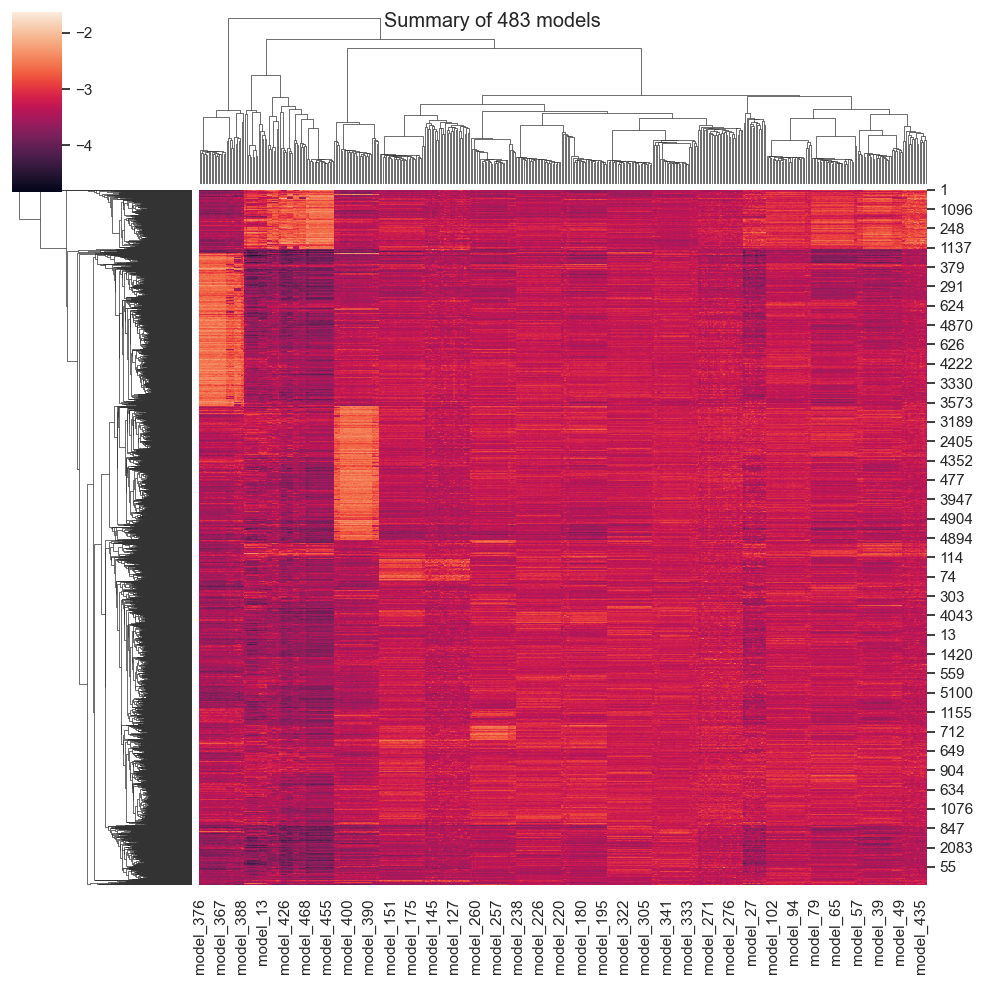

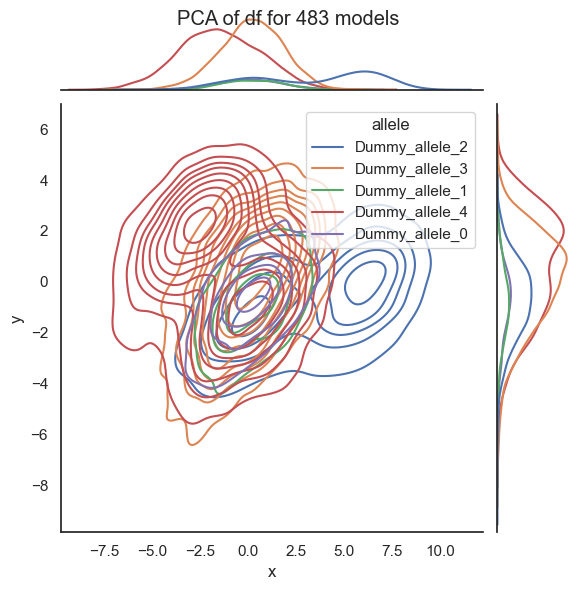

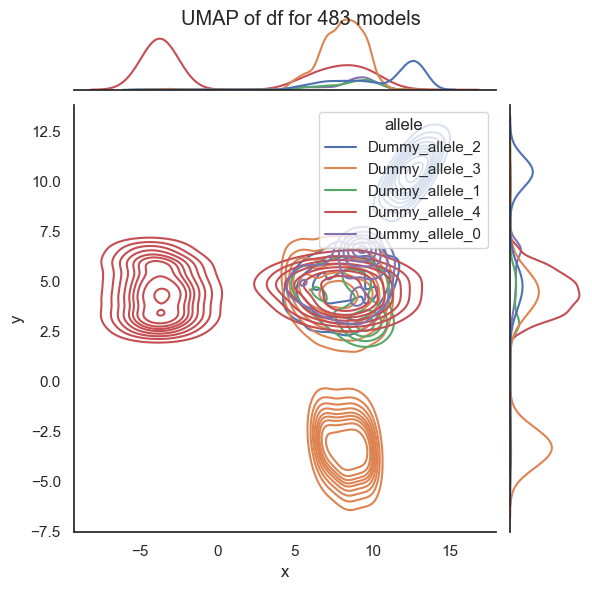

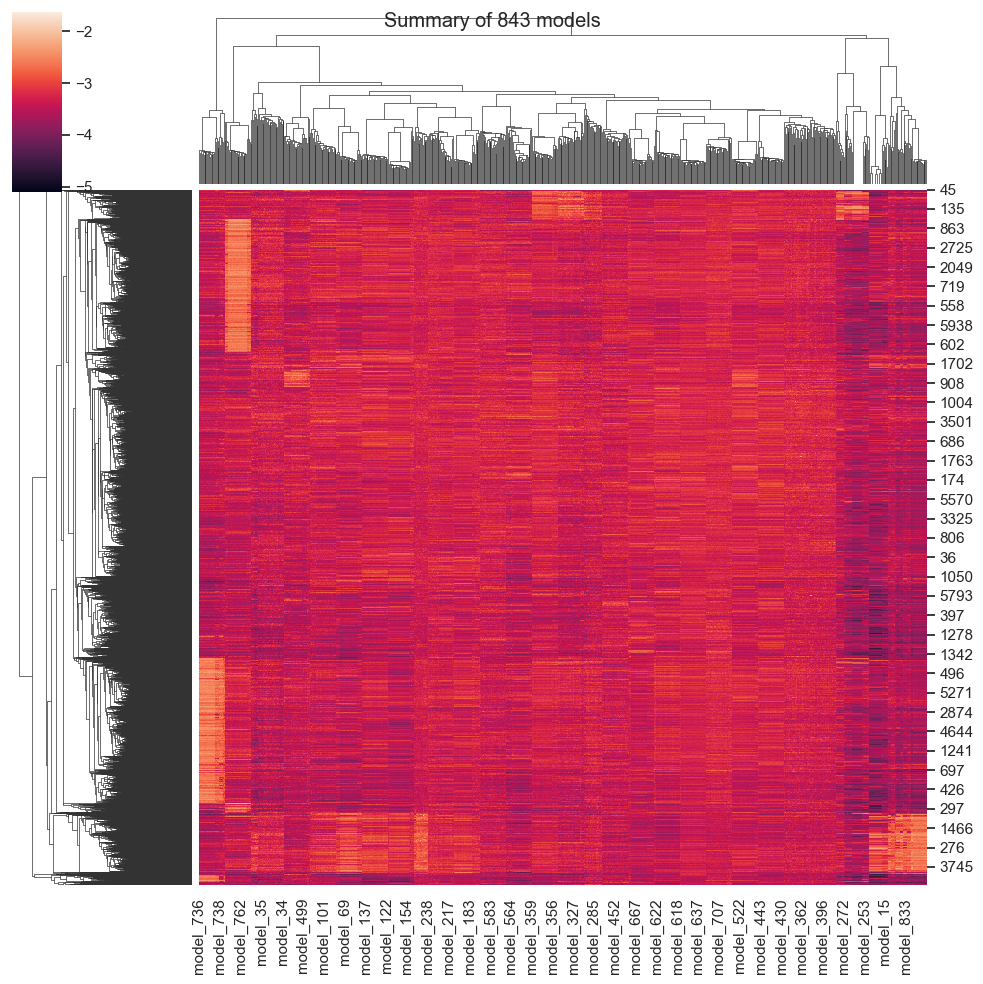

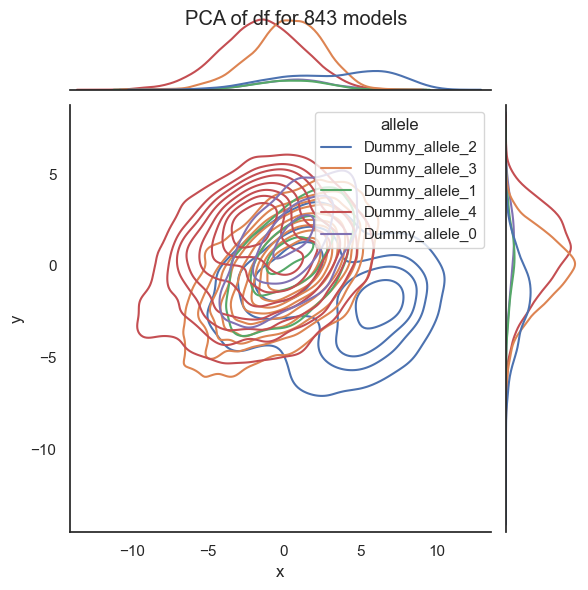

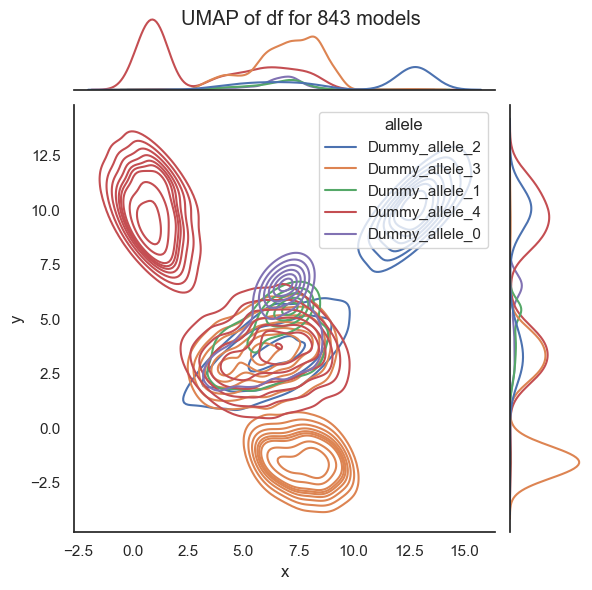

In [20]:
%%time
hierarchically_train_splited_models(per_name_models=per_name_models,
                                    train_data=train_data,
                                    test_data=test_data,
                                    additional_data=additional_data,
                                    experiment_params=hmm_params,
                                    total_layers_to_do=6)

# Legacy below this point

# Base models trained. Now we want to estimate splits.
##  Try to enrich main motif

### First sort peptides by score and visualize probability

In [21]:
import importlib
import hmm_logic_methods
import hmm_visualization_methods
hmm_logic_methods= importlib.reload(hmm_logic_methods)
hmm_visualization_methods= importlib.reload(hmm_visualization_methods)
from hmm_logic_methods import get_all_scores_and_sort_by_best
from hmm_visualization_methods import plot_all_scores_as_lines, plot_all_scores_as_separate_lines, plot_split_diagnostics

In [ ]:
per_allele_data_df = get_all_scores_and_sort_by_best(train_data, per_name_models)


currently take only 1 split


In [ ]:
target_df = plot_all_scores_as_lines(per_allele_data_df, per_name_models)

In [ ]:
plot_all_scores_as_separate_lines(per_allele_data_df, per_name_models)


In [ ]:
t = plot_split_diagnostics(per_allele_data_df, additional)

## Split code

In [ ]:
import math

In [ ]:
# def split_model(per_name_models, train_data, iteration, split_type = 0.5, original_model_index=0):
#     ####!!!! TODO: change to per allele model
#    # selected_model = get_average_model_for_runs(per_name_models)
#     selected_model = per_name_models[list(per_name_models.keys())[original_model_index]]
#     ####!!!
#     per_allele_list_of_dfs = defaultdict(list)
#     for allele_name in ALLELES:
#         for current_split in range(TOTAL_SPLITS):
#             for current_length in TARGET_LENGTHS:
#                 peptides = train_data[allele_name][current_split][current_length]
#                 df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
#                 per_allele_list_of_dfs[allele_name].append(df)
#
#     per_allele_data_df = dict()
#     per_allele_first_df = dict()
#     per_allele_second_df =dict()
#     for allele_name in ALLELES:
#         df = pd.concat(per_allele_list_of_dfs[allele_name])
#         df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
#         df = df.sort_values(by='score', ascending=False)
#         #df1 = df.loc[df.score > -3].copy()
#         #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
#         #df1 = df[df['score'] >= df['score'].max() - np.log(2)].copy()
#         #df2 = df[df['score'] < df['score'].max() - np.log(2)].copy()
#         df1 = df[df['score'] >= df['score'].mean()].copy()
#         df2 = df[df['score'] < df['score'].mean()].copy()
#         per_allele_first_df[allele_name] = df1
#         per_allele_second_df[allele_name] = df2
#         per_allele_data_df[allele_name] = df
#     new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
#     new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
#     train_data_weights1 = get_weights(new_train_data1)
#     train_data_weights2 = get_weights(new_train_data2)
#     per_allele_per_run_per_split_prepared_models1 = prepare_all_models()
#     per_allele_per_run_per_split_prepared_models2 = prepare_all_models()
#
#     #1
#     per_allele_per_run_per_split_prepared_models1, \
#     per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
#                                                                   test_data=test_data,
#                                                                   train_data_weights=train_data_weights1,
#                                                                   save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
#                                                                   prepared_models=per_allele_per_run_per_split_prepared_models1
#                                                                   )
#     #2
#     per_allele_per_run_per_split_prepared_models2, \
#     per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
#                                                                   test_data=test_data,
#                                                                   train_data_weights=train_data_weights2,
#                                                                   save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
#                                                                   prepared_models=per_allele_per_run_per_split_prepared_models2
#                                                                   )
#     per_name_models1, per_name_histories1 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
#                                                                 models=per_allele_per_run_per_split_prepared_models1)
#     per_name_models2, per_name_histories2 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
#                                                                     models=per_allele_per_run_per_split_prepared_models2)
#     save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
#     save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')
#
#     return per_name_models1, per_name_models2, new_train_data1, new_train_data2





## Make all splits

In [ ]:
NUM_RUNS = 8
NUM_RUNS

In [ ]:
from data_reading_methods import split_to_dicts

def split_model_and_enrich(per_name_models, train_data, iteration,
                           split_type = 0.5,
                           original_model_index=0,
                           enrichment_steps = 3,
                           NUM_RUNS =20,
                           DECREASE_ANCHOR_ACIDS_STEPS = 1,
                           model_index_start=0):
    ####!!!! TODO: change to per allele model
   # selected_model = get_average_model_for_runs(per_name_models)
    selected_model = per_name_models[list(per_name_models.keys())[original_model_index]]
    ####!!!
    per_allele_list_of_dfs = defaultdict(list)
    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)

    per_allele_data_df = dict()
    per_allele_first_df = dict()
    per_allele_second_df =dict()
    for allele_name in ALLELES:
        df = pd.concat(per_allele_list_of_dfs[allele_name])
        df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        df = df.sort_values(by='score', ascending=False)
        #df1 = df.loc[df.score > -3].copy()
        #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
        #df1 = df[df['score'] >= df['score'].max() - np.log(2)].copy()
        #df2 = df[df['score'] < df['score'].max() - np.log(2)].copy()
        df1 = df[df['score'] >= df['score'].mean()].copy()
        df2 = df[df['score'] < df['score'].mean()].copy()
        per_allele_first_df[allele_name] = df1
        per_allele_second_df[allele_name] = df2
        per_allele_data_df[allele_name] = df
    new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
    new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
    train_data_weights1 = get_weights(new_train_data1)
    train_data_weights2 = get_weights(new_train_data2)
    per_allele_per_run_per_split_prepared_models1 = prepare_all_models(RUN_START=model_index_start,
                                                                       NUM_RUNS=NUM_RUNS,
                                                                       DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
    per_allele_per_run_per_split_prepared_models2 = prepare_all_models(RUN_START=model_index_start + NUM_RUNS*DECREASE_ANCHOR_ACIDS_STEPS,
                                                                       NUM_RUNS=NUM_RUNS,
                                                                       DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)

    #1
    per_allele_per_run_per_split_prepared_models1, \
    per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                                  test_data=test_data,
                                                                  train_data_weights=train_data_weights1,
                                                                  save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                                  prepared_models=per_allele_per_run_per_split_prepared_models1
                                                                  )
    #2
    per_allele_per_run_per_split_prepared_models2, \
    per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                                  test_data=test_data,
                                                                  train_data_weights=train_data_weights2,
                                                                  save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                                  prepared_models=per_allele_per_run_per_split_prepared_models2
                                                                  )
    per_name_models1, per_name_histories1,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                                models=per_allele_per_run_per_split_prepared_models1)
    per_name_models2, per_name_histories2,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                    models=per_allele_per_run_per_split_prepared_models2)

    # ## Here we want to plot UMAP for freshly splited models
    # total_models = dict()
    # total_models.update(per_name_models1)
    # total_models.update(per_name_models2)
    # print(f"length of models is {len(total_models)}" )
    # per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
    # plot_split_diagnostics(per_allele_scores_data, additional)



    ## enrichment step
    print("Enrichment")
    for i in range(enrichment_steps):
        print("enrichment iteration", i)
        for allele_name in ALLELES:
            df = per_allele_data_df[allele_name]
            selected_model1 = per_name_models1[list(per_name_models1)[0]]
            selected_model2 = per_name_models2[list(per_name_models2)[0]]
            df[f'score1_step{i}'] = [selected_model1.log_probability(peptide)/len(peptide) for peptide in df.peptide]
            df[f'score2_step{i}'] = [selected_model2.log_probability(peptide)/len(peptide) for peptide in df.peptide]
            df1 = df[df[f'score1_step{i}'] >= df[f'score2_step{i}']].copy()
            df2 = df[df[f'score2_step{i}'] >= df[f'score1_step{i}']].copy()
            per_allele_first_df[allele_name] = df1
            per_allele_second_df[allele_name] = df2
            per_allele_data_df[allele_name] = df
        new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        train_data_weights1 = get_weights(new_train_data1)
        train_data_weights2 = get_weights(new_train_data2)
        per_allele_per_run_per_split_prepared_models1 = prepare_all_models(RUN_START=model_index_start,
                                                                           NUM_RUNS=NUM_RUNS,
                                                                           DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
        per_allele_per_run_per_split_prepared_models2 = prepare_all_models(RUN_START=model_index_start + NUM_RUNS*DECREASE_ANCHOR_ACIDS_STEPS,
                                                                           NUM_RUNS=NUM_RUNS,
                                                                           DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
         #1
        print(f"Model {iteration}1")
        per_allele_per_run_per_split_prepared_models1, \
        per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                                      test_data=test_data,
                                                                      train_data_weights=train_data_weights1,
                                                                      save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                                      prepared_models=per_allele_per_run_per_split_prepared_models1
                                                                      )
        #2
        print(f"Model {iteration}2")
        per_allele_per_run_per_split_prepared_models2, \
        per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                                      test_data=test_data,
                                                                      train_data_weights=train_data_weights2,
                                                                      save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                                      prepared_models=per_allele_per_run_per_split_prepared_models2
                                                                      )
        per_name_models1, per_name_histories1,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                                    models=per_allele_per_run_per_split_prepared_models1)
        per_name_models2, per_name_histories2,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                        models=per_allele_per_run_per_split_prepared_models2)

    save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
    save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')

    return per_name_models1, per_name_models2, new_train_data1, new_train_data2, per_allele_data_df


In [ ]:
%%time
from collections import deque
import sys
orig_stdout = sys.stdout
with open('out.txt', 'w') as f:
  #  sys.stdout = f
    # try single split and multiple enrichments
    stats_storage = dict()
    iteration = "1"
    models_deque = deque()
    data_deque = deque()
    iteration_deque = deque()

    models_deque.append(per_name_models)
    data_deque.append(train_data)
    iteration_deque.append("1")

    total_models = dict()

    for i in range(7):
        per_name_current_models = models_deque.popleft()
        this_train_data = data_deque.popleft()
        iteration = iteration_deque.popleft()
        print("iteration", iteration)
        # run current data
        per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=3, model_index_start=len(total_models),NUM_RUNS=NUM_RUNS, DECREASE_ANCHOR_ACIDS_STEPS=2 )
        # Add current models to the total representation and visualize UMAP of this representation
        total_models.update(per_name_models1)
        total_models.update(per_name_models2)
        print(f"length of models is {len(total_models)}" )
        per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
        plot_split_diagnostics(per_allele_scores_data, additional)

        # add left to queue
        models_deque.append(per_name_models1)
        stats_storage[iteration] = enrichmenet_stats

        #data_deque.append(new_train_data1)
        # add whole train data
        data_deque.append(new_train_data1)
        iteration_deque.append(f'{iteration}1')
        models_deque.append(per_name_models2)
        data_deque.append(new_train_data2)
        # add whole train data
       # data_deque.append(train_data)
        iteration_deque.append(f'{iteration}2')
        if i in {0, 2, 6}:
            params['emission_pseudocount']=  params['emission_pseudocount']/2
        if i in {0, 2, 6}:
            #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
            #params['anchor_top_aas'] = params['anchor_top_aas'] - 1
            pass
        if i in {0, 2, 6}:
            # make total data df (should be per allele)
            per_allele_list_of_dfs = defaultdict(list)
            for allele_name in ALLELES:
                for current_split in range(TOTAL_SPLITS):
                    for current_length in TARGET_LENGTHS:
                        peptides = train_data[allele_name][current_split][current_length]
                        df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                        per_allele_list_of_dfs[allele_name].append(df)
            #
            per_allele_X_matrix = dict()
            for allele_name in ALLELES:
                total_data = pd.concat(per_allele_list_of_dfs[allele_name])
                for model_num in range(len(models_deque)):
                    current_models = models_deque[model_num]
                    selected_model = current_models[list(current_models.keys())[0]]
                    total_data[f'score_general_{model_num}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in total_data.peptide]
                X_matrix = total_data[[f'score_general_{i}' for i in range(len(models_deque))]].copy()
                X_matrix['max_column'] = X_matrix.idxmax(axis=1)
            #
                per_allele_X_matrix[allele_name] = X_matrix
            #
            new_train_data = list()
            for model_num in range(len(models_deque)):
                per_allele_new_df = dict()
                for allele_name in ALLELES:
                    X_matrix = per_allele_X_matrix[allele_name]
                    new_df = total_data[X_matrix['max_column'] == f'score_general_{model_num}'].copy()
                    per_allele_new_df[allele_name] =new_df
                new_train_data = split_to_dicts(per_allele_new_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
                data_deque[model_num] = new_train_data
                # nor we want to reorder all peptides according to scores of 2-4-6-8
   # sys.stdout = orig_stdout





In [ ]:
per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
df = per_allele_scores_data[allele_name]
target_df = df[[col for col in df.columns if col.startswith("model")]]
sns.clustermap(target_df)

In [ ]:
sns.clustermap(target_df, metric="correlation" )



## Analyze stats

In [ ]:
df = per_allele_scores_data[ALLELES[0]]

In [ ]:
pd

In [ ]:
t = dict()
t['model_1x'] = list(df.model_1.values)
t['model_12']= list(df.model_2.values)
t['model_3x'] = list(df.model_3.values)

In [ ]:
pd.concat([df, pd.DataFrame(t, index=df.index )], axis=1)

In [ ]:
df

In [ ]:
df = per_allele_scores_data[allele_name]
target_df = df[[col for col in df.columns if col.startswith("model")]]
sns.clustermap(target_df)
pca = PCA(n_components=30)
pca_result = pca.fit_transform(target_df.values)
ann_df = additional[0][allele_name]
ann_df = ann_df[ann_df.split == 0]
print("this method supports 1 split for now")
ann_df = ann_df[['peptide', 'allele']]
annotated_df = df.merge(ann_df, on='peptide', how='left', validate='1:1')
to_plot = pd.DataFrame({"x": pca_result[:, 1], "y": pca_result[:, 2], "allele":annotated_df.allele.values})
sns.jointplot(to_plot, x="x", y="y", hue="allele", kind='kde')
fit = umap.UMAP()
u = fit.fit_transform(pca_result)
to_plot = pd.DataFrame({"x": u[:, 0], "y": u[:, 1], "allele": annotated_df.allele.values, "peptide": annotated_df.peptide.values})
sns.jointplot(to_plot, x="x", y="y", hue='allele', kind='kde')

In [ ]:
stats_storage.keys()

In [ ]:
enrichmenet_stats = stats_storage["11"]

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

In [ ]:
df1 = df[df['score'] >= df['score'].mean()].copy()
df2 = df[df['score'] < df['score'].mean()].copy()
len(df1), len(df2)

In [ ]:
lengths = list()
for step in range(5):
    #print("Step", step)
    df1 = df[df[f'score1_step{step}'] >= df[f'score2_step{step}']].copy()
    df2 = df[df[f'score2_step{step}'] >= df[f'score1_step{step}']].copy()
    lengths.append(f"{len(df1)}/{len(df2)}")

print(" -> ".join(lengths))

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 0
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 1
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 2
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 3
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 4
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

## Make additional splits

In [ ]:
a = [iteration_deque.popleft() for i in range(6)]
m = [models_deque.popleft() for i in range(6)]
d = [data_deque.popleft() for i in range(6)]

In [ ]:
iteration_deque

In [ ]:
per_name_current_models = models_deque.popleft()
this_train_data = data_deque.popleft()
iteration = iteration_deque.popleft()
print("iteration", iteration)
# run current data
per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=5)
# add left to queue
models_deque.append(per_name_models1)
stats_storage[iteration] = enrichmenet_stats

#data_deque.append(new_train_data1)
# add whole train data
data_deque.append(new_train_data1)
iteration_deque.append(f'{iteration}1')
models_deque.append(per_name_models2)
data_deque.append(new_train_data2)
# add whole train data
# data_deque.append(train_data)
iteration_deque.append(f'{iteration}2')
if i in {0, 2, 6}:
    #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
    params['emission_pseudocount']=  params['emission_pseudocount']/2
if i in {0, 2, 6}:
    # make total data df (should be per allele)
    per_allele_list_of_dfs = defaultdict(list)
    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)
    #
    per_allele_X_matrix = dict()
    for allele_name in ALLELES:
        total_data = pd.concat(per_allele_list_of_dfs[allele_name])
        for model_num in range(len(models_deque)):
            current_models = models_deque[model_num]
            selected_model = current_models[list(current_models.keys())[0]]
            total_data[f'score_general_{model_num}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in total_data.peptide]
        X_matrix = total_data[[f'score_general_{i}' for i in range(len(models_deque))]].copy()
        X_matrix['max_column'] = X_matrix.idxmax(axis=1)
    #
        per_allele_X_matrix[allele_name] = X_matrix
    #
    new_train_data = list()
    for model_num in range(len(models_deque)):
        per_allele_new_df = dict()
        for allele_name in ALLELES:
            X_matrix = per_allele_X_matrix[allele_name]
            new_df = total_data[X_matrix['max_column'] == f'score_general_{model_num}'].copy()
            per_allele_new_df[allele_name] =new_df
        new_train_data = split_to_dicts(per_allele_new_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        data_deque[model_num] = new_train_data
        # nor we want to reorder all peptides according to scores of 2-4-6-8

In [ ]:
NUM_RUNS = 3

In [ ]:
from collections import deque

# try two splits  and multiple enrichments
stats_storage = dict()
iteration = "1"
models_deque = deque()
data_deque = deque()
iteration_deque = deque()

models_deque.append(per_name_models)
data_deque.append(train_data)
iteration_deque.append("1")

for i in range(3):
    per_name_current_models = models_deque.popleft()
    this_train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=5)
    # add left to queue
    models_deque.append(per_name_models1)
    stats_storage[iteration] = enrichmenet_stats
    #data_deque.append(new_train_data1)
    # add whole train data
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    # add whole train data
   # data_deque.append(train_data)
    iteration_deque.append(f'{iteration}2')
    if i in {0, 2, 6}:
        #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
        params['emission_pseudocount']=  params['emission_pseudocount']/2



In [ ]:
current_step = 3
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
enrichmenet_stats[ALLELES[0]]

## Make all splits

In [ ]:
for i in range(7):
    per_name_current_models = models_deque.popleft()
    this_train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_current_models, this_train_data, iteration)
    # add left to queue
    models_deque.append(per_name_models1)

    #data_deque.append(new_train_data1)
    # add whole train data
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    # add whole train data
   # data_deque.append(train_data)
    iteration_deque.append(f'{iteration}2')
    if i in {0, 2, 6}:
        #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
        params['emission_pseudocount']=  params['emission_pseudocount']/2

In [ ]:
from collections import deque

result_models1 = list()
result_models2 = list()
result_train_data1 = list()
result_train_data2 = list()
iteration = "1"
split_types = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

for split_type in split_types:
    split_type = round(split_type, 2)
    rest_part = np.round(split_type, 2)
    iteration = f"-({split_type},{rest_part})-"
    #pet_name models is the same base model
    #train_data is the same train data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration, split_type=split_type)
    result_models1.append(per_name_models1)
    result_models2.append(per_name_models2)
    result_train_data1.append(new_train_data1)
    result_train_data2.append(new_train_data2)


In [ ]:
len(result_models1)

## Show scores for splited models

In [ ]:
def get_average_model_for_runs(per_name_models):
    example_model = per_name_models[list(per_name_models.keys())[0]]
    transition_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states), len(example_model.states)))
    emission_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states)-2, 20))

    for i, model in enumerate(per_name_models.values()):
        transition_matrix_cube[i, :, :] = model.dense_transition_matrix()
        for j,state in enumerate(model.states):
            if state.distribution is not None:
                params = list(state.distribution.parameters[0].values())
                emission_matrix_cube[i, j, :] = np.array(params)

    mean_emission_table = np.median(emission_matrix_cube, axis=0)
    mean_transition_table = np.median(transition_matrix_cube, axis=0)

    distributions = []
    amino_acids_list = list('ACDEFGHIKLMNPQRSTVWY')
    for j in range(len(example_model.states)-2):
        d_dict = {key: prob for key, prob in zip(amino_acids_list, mean_emission_table[j, :])}
        curr_distribution = DiscreteDistribution(d_dict)
        distributions.append(curr_distribution)

    model = HiddenMarkovModel.from_matrix(
        name="average model",
        transition_probabilities=mean_transition_table[:-2,:-2],
        starts=mean_transition_table[-2, :],
        distributions=distributions,
        ends=mean_transition_table[:, -1],
        state_names = ["s{:03d}".format(i) for i in range(len(example_model.states)-2)],
        verbose=True)
    model.bake()
    return model

In [ ]:
per_allele_list_of_dfs = defaultdict(list)

for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
for allele_name in ALLELES:
    per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for i, model in enumerate(per_name_models.values()):
        df[f'model_{i}'] = [model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        df = df.sort_values(by='model_0', ascending=False)
        per_allele_data_df[allele_name] = df

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for current_split, models_dict in zip(split_types,result_models1):
        selected_model = get_average_model_for_runs(models_dict)
        df[f'model_{current_split}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        per_allele_data_df[allele_name] = df

In [ ]:
per_allele_data_df[allele_name]

In [ ]:
df = df.reset_index(drop=True)
target_df =df.melt(id_vars=['peptide'],value_vars=['model_0'] + [f'model_{i}' for i in split_types], value_name = 'score', var_name='model', ignore_index=False)

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for current_split, models_dict in zip(split_types,result_models2):
        selected_model = get_average_model_for_runs(models_dict)
        df[f'model_{current_split}_alt'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        per_allele_data_df[allele_name] = df

In [ ]:
per_allele_data_df[allele_name]
df = df.reset_index(drop=True)
target_df = df.melt(id_vars=['peptide'], value_vars=['model_0'] + [f'model_{i}_alt' for i in split_types],
                    value_name='score', var_name='model', ignore_index=False)

In [ ]:
target_df

In [ ]:
df

In [ ]:
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
target_model = 0.7
new_df = df.sort_values(by=f'model_0', ascending=False)
new_df = new_df.reset_index(drop=True)
target_df = new_df.melt(id_vars=['peptide'], value_vars=['model_0'] + [f'model_{i}_alt' for i in [ target_model]] + [f'model_{i}' for i in [target_model]],
                    value_name='score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# Calculate scores for dataset

In [ ]:
def get_average_model_for_runs(per_name_models):
    example_model = per_name_models[list(per_name_models.keys())[0]]
    transition_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states), len(example_model.states)))
    emission_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states)-2, 20))

    for i, model in enumerate(per_name_models.values()):
        transition_matrix_cube[i, :, :] = model.dense_transition_matrix()
        for j,state in enumerate(model.states):
            if state.distribution is not None:
                params = list(state.distribution.parameters[0].values())
                emission_matrix_cube[i, j, :] = np.array(params)

    mean_emission_table = np.median(emission_matrix_cube, axis=0)
    mean_transition_table = np.median(transition_matrix_cube, axis=0)

    distributions = []
    amino_acids_list = list('ACDEFGHIKLMNPQRSTVWY')
    for j in range(len(example_model.states)-2):
        d_dict = {key: prob for key, prob in zip(amino_acids_list, mean_emission_table[j, :])}
        curr_distribution = DiscreteDistribution(d_dict)
        distributions.append(curr_distribution)

    model = HiddenMarkovModel.from_matrix(
        name="average model",
        transition_probabilities=mean_transition_table[:-2,:-2],
        starts=mean_transition_table[-2, :],
        distributions=distributions,
        ends=mean_transition_table[:, -1],
        state_names = ["s{:03d}".format(i) for i in range(len(example_model.states)-2)],
        verbose=True)
    model.bake()
    return model

In [ ]:
selected_model = get_average_model_for_runs(per_name_models)

In [ ]:
per_allele_list_of_dfs = defaultdict(list)

for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
for allele_name in ALLELES:
    per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])

In [ ]:
per_allele_data_df[ALLELES[0]]

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    per_allele_data_df[allele_name] = df

In [ ]:
df

In [ ]:
df[df.score > -3].length.value_counts()

In [ ]:
df1 = df.loc[df.score > -3].copy()
df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()

In [ ]:
df1

In [ ]:
df[df.index.isin(df1.index)]

In [ ]:
per_allele_data_df[allele_name].to_csv('original_predictions.csv', sep=';')

# Get top 50% in one dataset another top 50% in another

In [ ]:
import seaborn as sns

In [ ]:
per_allele_first_df = dict()
per_allele_second_df = dict()
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    df1 = df.iloc[:int(len(df)/2)].copy()
    df2 = df.iloc[int(len(df)/2):].copy()
    per_allele_first_df[allele_name] = df1
    per_allele_second_df[allele_name] = df2
    per_allele_data_df[allele_name] = df

In [ ]:
sns.displot(df, x='score')

## Iterations of such procedure

In [ ]:
len(train_data[ALLELES[0]][0][15])

## Train models for different splits based on single one

In [ ]:
from collections import deque

iteration = "1"
split_types = np.linspace(0.05, 0.95, num=20)


for split_type in split_types:
    split_type = round(split_type, 2)
    rest_part =round(1-split_type, 2)
    iteration = f"-({split_type},{rest_part})-"
    #pet_name models is the same base model
    #train_data is the same train data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration, split_type=split_type)


In [ ]:
split_type = round(split_types[2], 2)
iteration = f"-({split_type},{1-split_type})-"

In [ ]:
split_type

In [ ]:
####!!!! TODO: change to per allele model
# selected_model = get_average_model_for_runs(per_name_models)
selected_model = per_name_models[list(per_name_models.keys())[0]]
####!!!
per_allele_list_of_dfs = defaultdict(list)
for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
per_allele_first_df = dict()
per_allele_second_df =dict()
for allele_name in ALLELES:
    df = pd.concat(per_allele_list_of_dfs[allele_name])
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    #df1 = df.loc[df.score > -3].copy()
    #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
    df1 = df.iloc[:int(len(df)*split_type)].copy()
    df2 = df.iloc[int(len(df)*split_type):].copy()
    per_allele_first_df[allele_name] = df1
    per_allele_second_df[allele_name] = df2
    per_allele_data_df[allele_name] = df
new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
train_data_weights1 = get_weights(new_train_data1, old_test_data)
train_data_weights2 = get_weights(new_train_data2, old_test_data)
per_allele_per_run_per_split_prepared_models1 = prepare_all_models()
per_allele_per_run_per_split_prepared_models2 = prepare_all_models()

#1
per_allele_per_run_per_split_prepared_models1, \
per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                              test_data=test_data,
                                                              train_data_weights=train_data_weights1,
                                                              save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                              prepared_models=per_allele_per_run_per_split_prepared_models1
                                                              )
#2
per_allele_per_run_per_split_prepared_models2, \
per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                              test_data=test_data,
                                                              train_data_weights=train_data_weights2,
                                                              save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                              prepared_models=per_allele_per_run_per_split_prepared_models2
                                                              )
per_name_models1, per_name_histories1 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                            models=per_allele_per_run_per_split_prepared_models1)
per_name_models2, per_name_histories2 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                models=per_allele_per_run_per_split_prepared_models2)
save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')


In [ ]:
from collections import deque

iteration = "1"
models_deque = deque()
data_deque = deque()
iteration_deque = deque()

models_deque.append(per_name_models)
data_deque.append(train_data)
iteration_deque.append("1")

for i in range(3):
    per_name_models = models_deque.popleft()
    train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration)
    # add left to queue
    models_deque.append(per_name_models1)
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    iteration_deque.append(f'{iteration}2')



In [ ]:
df = join_dicts(train_data)

In [ ]:
df

In [ ]:
iteration

In [ ]:
iteration_deque